# Mall customer segmentation with K-Means

**Goal:** split 200 mall customers into segments the marketing team can act on, and show that the segments are real (not an artefact of one random seed or one algorithm).

**Data:** `data/mall_customers.csv`: customer ID, gender, age, annual income (k$), spending score (1–100, assigned by the mall from purchase behaviour).

All logic lives in the `segmentation/` package; this notebook runs it and shows the outputs.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/

import pandas as pd
from IPython.display import display
from segmentation import analysis, plots
from segmentation.data import FEATURES_2D, FEATURES_3D, load_customers
from segmentation.profiles import profile_segments
%matplotlib inline

pd.set_option("display.precision", 3)
df = load_customers()
print(df.shape)
df.head()

(200, 5)


,customer_id,gender,age,income_k,spending_score
0,0001,Male,19,15,39
1,0002,Male,21,15,81
2,0003,Female,20,16,6
3,0004,Female,23,16,77
4,0005,Female,31,17,40


## 1. Explore the data

In [2]:
display(df.describe().round(1))
print(df["gender"].value_counts())

,age,income_k,spending_score
count,200.0,200.0,200.0
mean,38.8,60.6,50.2
std,14.0,26.3,25.8
min,18.0,15.0,1.0
25%,28.8,41.5,34.8
50%,36.0,61.5,50.0
75%,49.0,78.0,73.0
max,70.0,137.0,99.0


gender
Female    112
Male       88
Name: count, dtype: int64


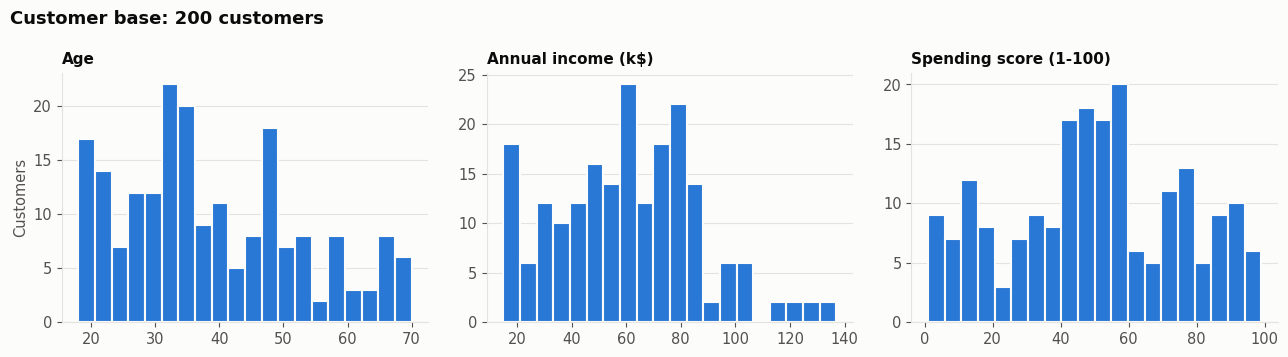

In [3]:
plots.distributions(df);

## 2. How many segments?

The original class demo picked K=5 from the elbow plot alone. Here four criteria are compared on **standardised** income and spending score.

In [4]:
scores = analysis.k_selection(df[FEATURES_2D])
display(scores.round(3))
print("Best K per index:", analysis.best_k(scores))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,269.691,0.321,1.267,95.669
1,3,157.704,0.467,0.716,151.335
2,4,108.921,0.494,0.710,174.595
3,5,65.568,0.555,0.572,248.649
4,6,55.057,0.540,0.655,243.088
5,7,44.865,0.528,0.715,254.621
6,8,37.148,0.457,0.758,267.914
7,9,32.392,0.457,0.763,270.948
8,10,29.686,0.436,0.765,263.350


Best K per index: {'silhouette': 5, 'davies_bouldin': 5, 'calinski_harabasz': 9}


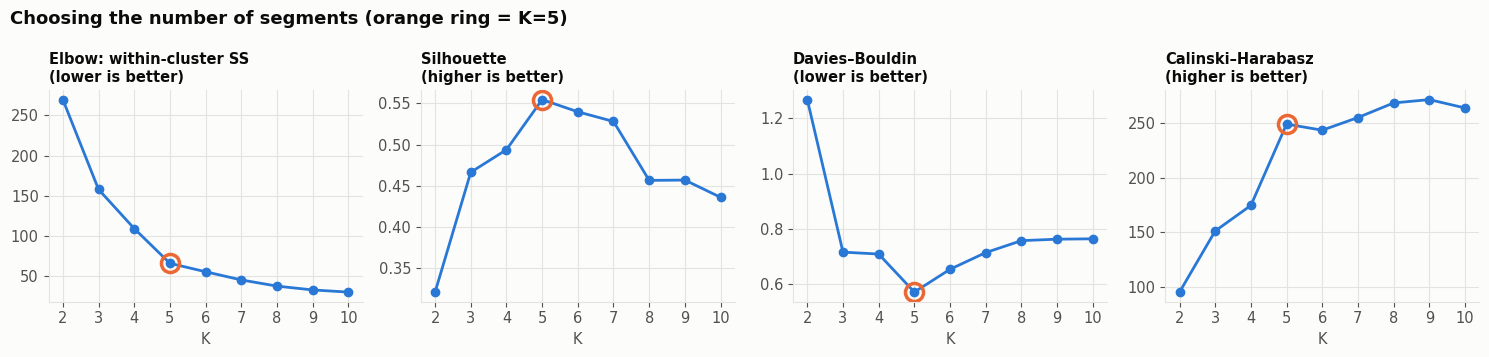

In [5]:
plots.k_selection(scores, chosen_k=5);

Silhouette and Davies–Bouldin both pick **K=5**, and the elbow bends there. Calinski–Harabasz keeps rising slowly (it tends to favour more clusters), but has a clear jump at 5.

Adding **age** as a third feature makes the structure less clear: the indices disagree (6 or 7) and silhouette drops, so the 2-feature view is used for the segments, with age reported per segment.

In [6]:
scores_3d = analysis.k_selection(df[FEATURES_3D])
display(scores_3d.round(3))
print("Best K per index (age + income + spending):", analysis.best_k(scores_3d))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,389.386,0.335,1.261,107.096
1,3,295.212,0.358,1.050,101.695
2,4,205.225,0.404,0.931,125.676
3,5,168.248,0.417,0.875,125.101
4,6,133.868,0.427,0.828,135.102
5,7,117.012,0.417,0.793,132.774
6,8,103.829,0.409,0.889,131.074
7,9,92.349,0.420,0.854,131.242
8,10,81.987,0.397,0.906,133.385


Best K per index (age + income + spending): {'silhouette': 6, 'davies_bouldin': 7, 'calinski_harabasz': 6}


## 3. Segment the customers (K=5)

In [7]:
model = analysis.fit_kmeans(df[FEATURES_2D], 5)
labels = model.predict(df[FEATURES_2D])
centers = model.named_steps["standardscaler"].inverse_transform(model.named_steps["kmeans"].cluster_centers_)
profiles = profile_segments(df, labels)
display(profiles.round(1))

,cluster,segment,customers,share_%,avg_income_k,avg_spending_score,avg_age,female_%,suggested_action
0,2,Impulsive budget shoppers,22,11.0,25.7,79.4,25.3,59.1,Promotions and bundles; watch credit/returns risk
1,4,Budget conscious,23,11.5,26.3,20.9,45.2,60.9,"Value ranges, discount days, low-cost retention"
2,0,Average customers,81,40.5,55.3,49.5,42.7,59.3,Standard campaigns; upsell toward the premium ...
3,1,Premium spenders,39,19.5,86.5,82.1,32.7,53.8,"Loyalty / VIP programme, early access, premium..."
4,3,Careful affluent,35,17.5,88.2,17.1,41.1,45.7,"Find out why they hold back: quality, service,..."


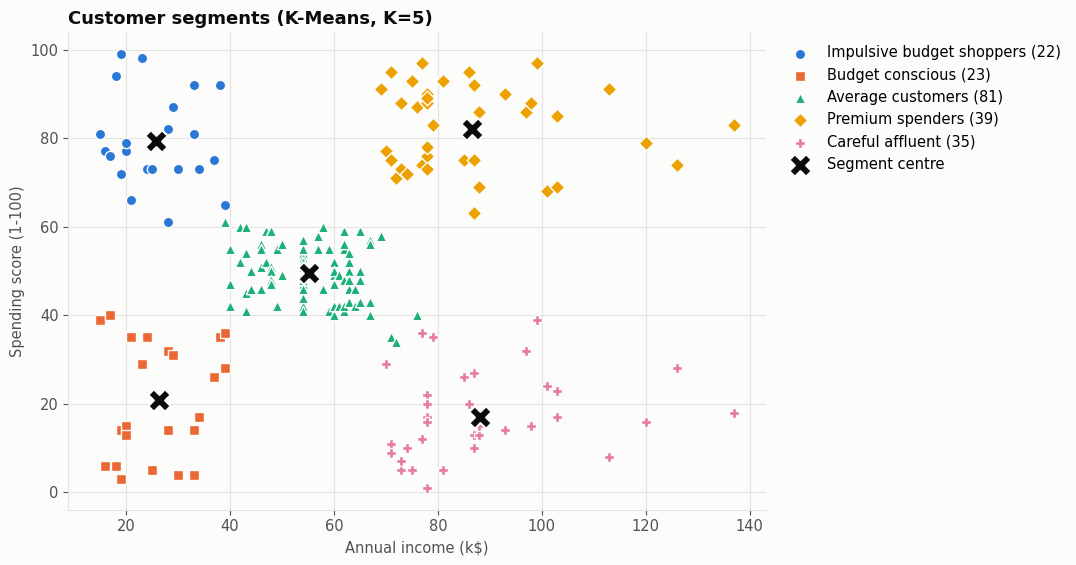

In [8]:
plots.segments_scatter(df, labels, profiles, centers);

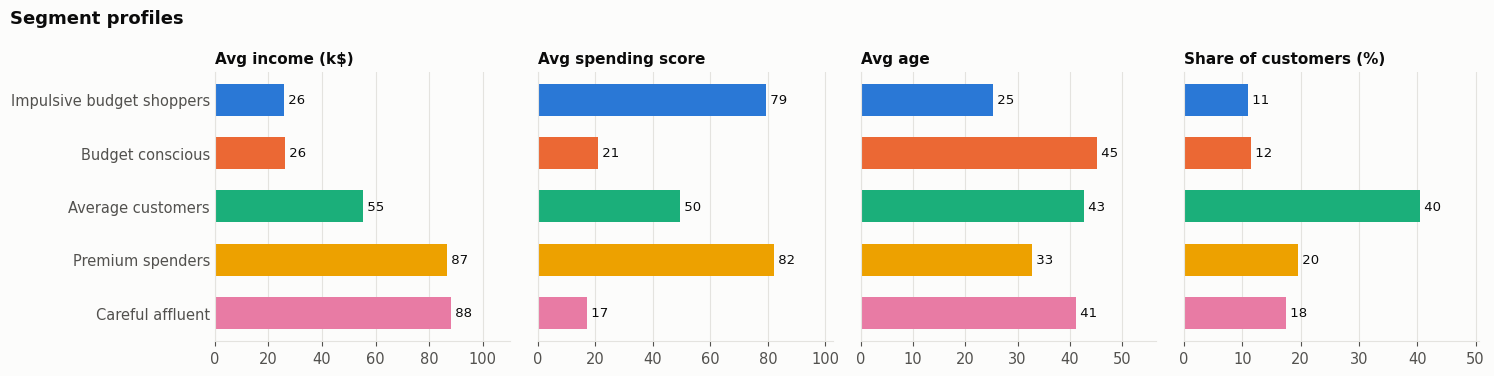

In [9]:
plots.profile_bars(profiles);

## 4. Are the segments stable?

Refit K-Means on 100 bootstrap resamples of the customers and compare each result with the full-data segmentation using the **Adjusted Rand Index** (1 = identical, 0 = random).

median ARI 0.973 | 5th percentile 0.929 | min 0.916


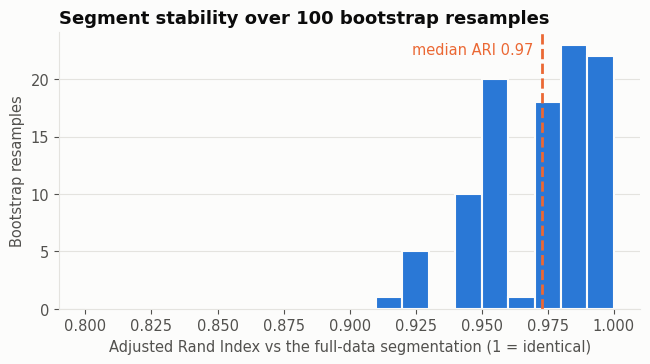

In [10]:
import numpy as np
aris = analysis.bootstrap_stability(df[FEATURES_2D], 5, n_boot=100)
print(f"median ARI {np.median(aris):.3f} | 5th percentile {np.percentile(aris, 5):.3f} | min {aris.min():.3f}")
plots.stability(aris);

## 5. Do other algorithms find the same segments?

,algorithm,silhouette,davies_bouldin,ARI vs K-Means
0,K-Means,0.555,0.572,1.000
1,Hierarchical (Ward),0.554,0.578,0.942
2,Gaussian mixture,0.554,0.576,0.956


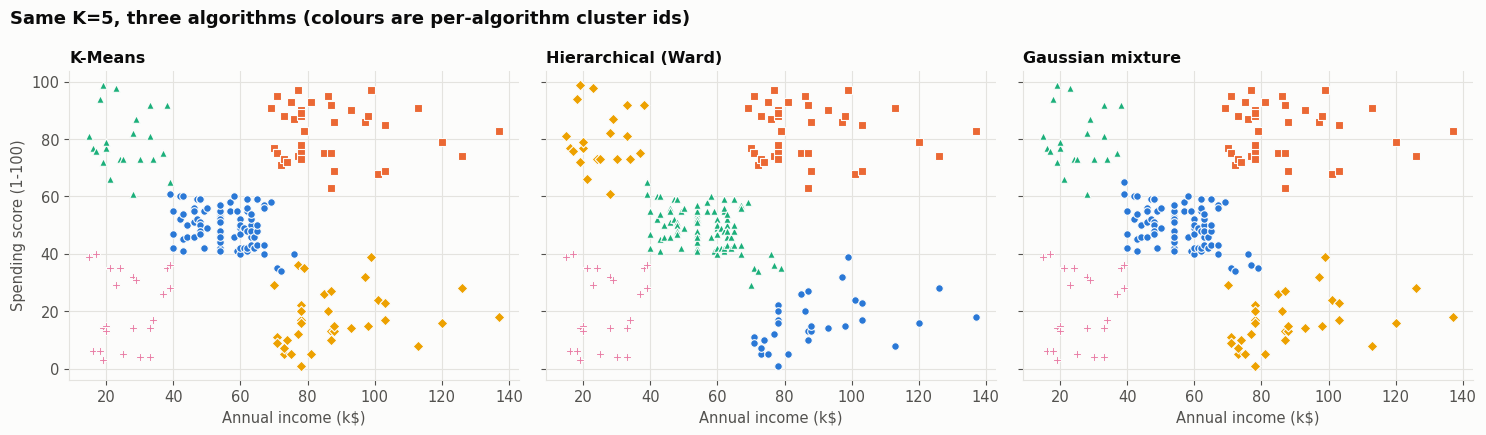

In [11]:
table, algo_labels = analysis.compare_algorithms(df[FEATURES_2D], 5)
display(table.round(3))
plots.algorithm_comparison(df, algo_labels);

Hierarchical clustering and a Gaussian mixture reach almost the same silhouette and agree with K-Means on ~95% of the structure (ARI 0.94–0.96). The few disagreements are customers on the border between *Average* and the four corner segments.

## 6. Assign new customers

In [12]:
from segmentation.predict import assign
names = dict(zip(profiles["cluster"], profiles["segment"]))
bundle = {"pipeline": model, "features": FEATURES_2D, "segment_names": names}
assign(bundle, income_k=[90, 25, 60, 100], spending_score=[85, 15, 50, 10])

,income_k,spending_score,cluster,segment
0,90,85,1,Premium spenders
1,25,15,4,Budget conscious
2,60,50,0,Average customers
3,100,10,3,Careful affluent


## Summary

| Segment | Who | Suggested action |
|---|---|---|
| Premium spenders | High income, high spending, ~33 years | VIP / loyalty programme, premium lines |
| Careful affluent | High income, low spending | Find out what holds them back; personalised offers |
| Impulsive budget shoppers | Low income, high spending, youngest (~25) | Promotions and bundles; watch credit risk |
| Budget conscious | Low income, low spending, ~45 years | Value ranges, discount days |
| Average customers | Middle income and spending (40% of customers) | Standard campaigns, upsell |

**Limitations:** 200 customers from one mall; the spending score is a black-box metric defined by the mall; no time dimension (segments can drift).